In [33]:
!pip install tensorflow


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\KESHAV\Deep-Learning\.venv\Lib\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedWriter name=5>
  res = process_handler(cmd, _system_body)
c:\Users\KESHAV\Deep-Learning\.venv\Lib\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=6>
  res = process_handler(cmd, _system_body)
c:\Users\KESHAV\Deep-Learning\.venv\Lib\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=7>
  res = process_handler(cmd, _system_body)


In [34]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [35]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings 
warnings.filterwarnings('default') #show warning while developing (use 'ignore' to ignore warnings)

plt.style.use('fivethirtyeight')
%matplotlib inline

##### In this dataset we have to predict the customer is going to use their bank account in future or they are leaving it 
##### If they are going to use then what extra benifit does the bank provide so the customer be with them for a long term 

In [36]:
df = pd.read_csv("churn_modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [37]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


## Exploratory Data Analysis(EDA)

In [39]:
# checking for null values
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [40]:
# dropping useless columns

df = df.drop(columns= ['RowNumber','CustomerId','Surname'])
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


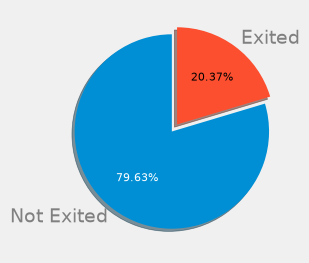

In [41]:
values = df.Exited.value_counts()
labels = ['Not Exited', 'Exited']

fig, ax = plt.subplots(figsize = (4,3), dpi = 100)
explode = (0, 0.09)

patches, texts, autotexts = ax.pie(values, labels = labels, autopct = '%1.2f%%', shadow =True, startangle =90, explode = explode)

plt.setp(texts, color = 'grey')
plt.setp(autotexts,size = 8, color = 'white')
autotexts[1].set_color('black')
plt.show()

## 20% of the customers have churned and 80% haven't
<pre>
  Variable	 Contains	                Purpose
1. patches	  Pie slice objects	        Customize slice colors, borders, etc.
2. texts	  Category label objects       Customize labels such as "Exited"
3. autotext      Percentage text objects       Customize values such as "20.37%"
</pre>

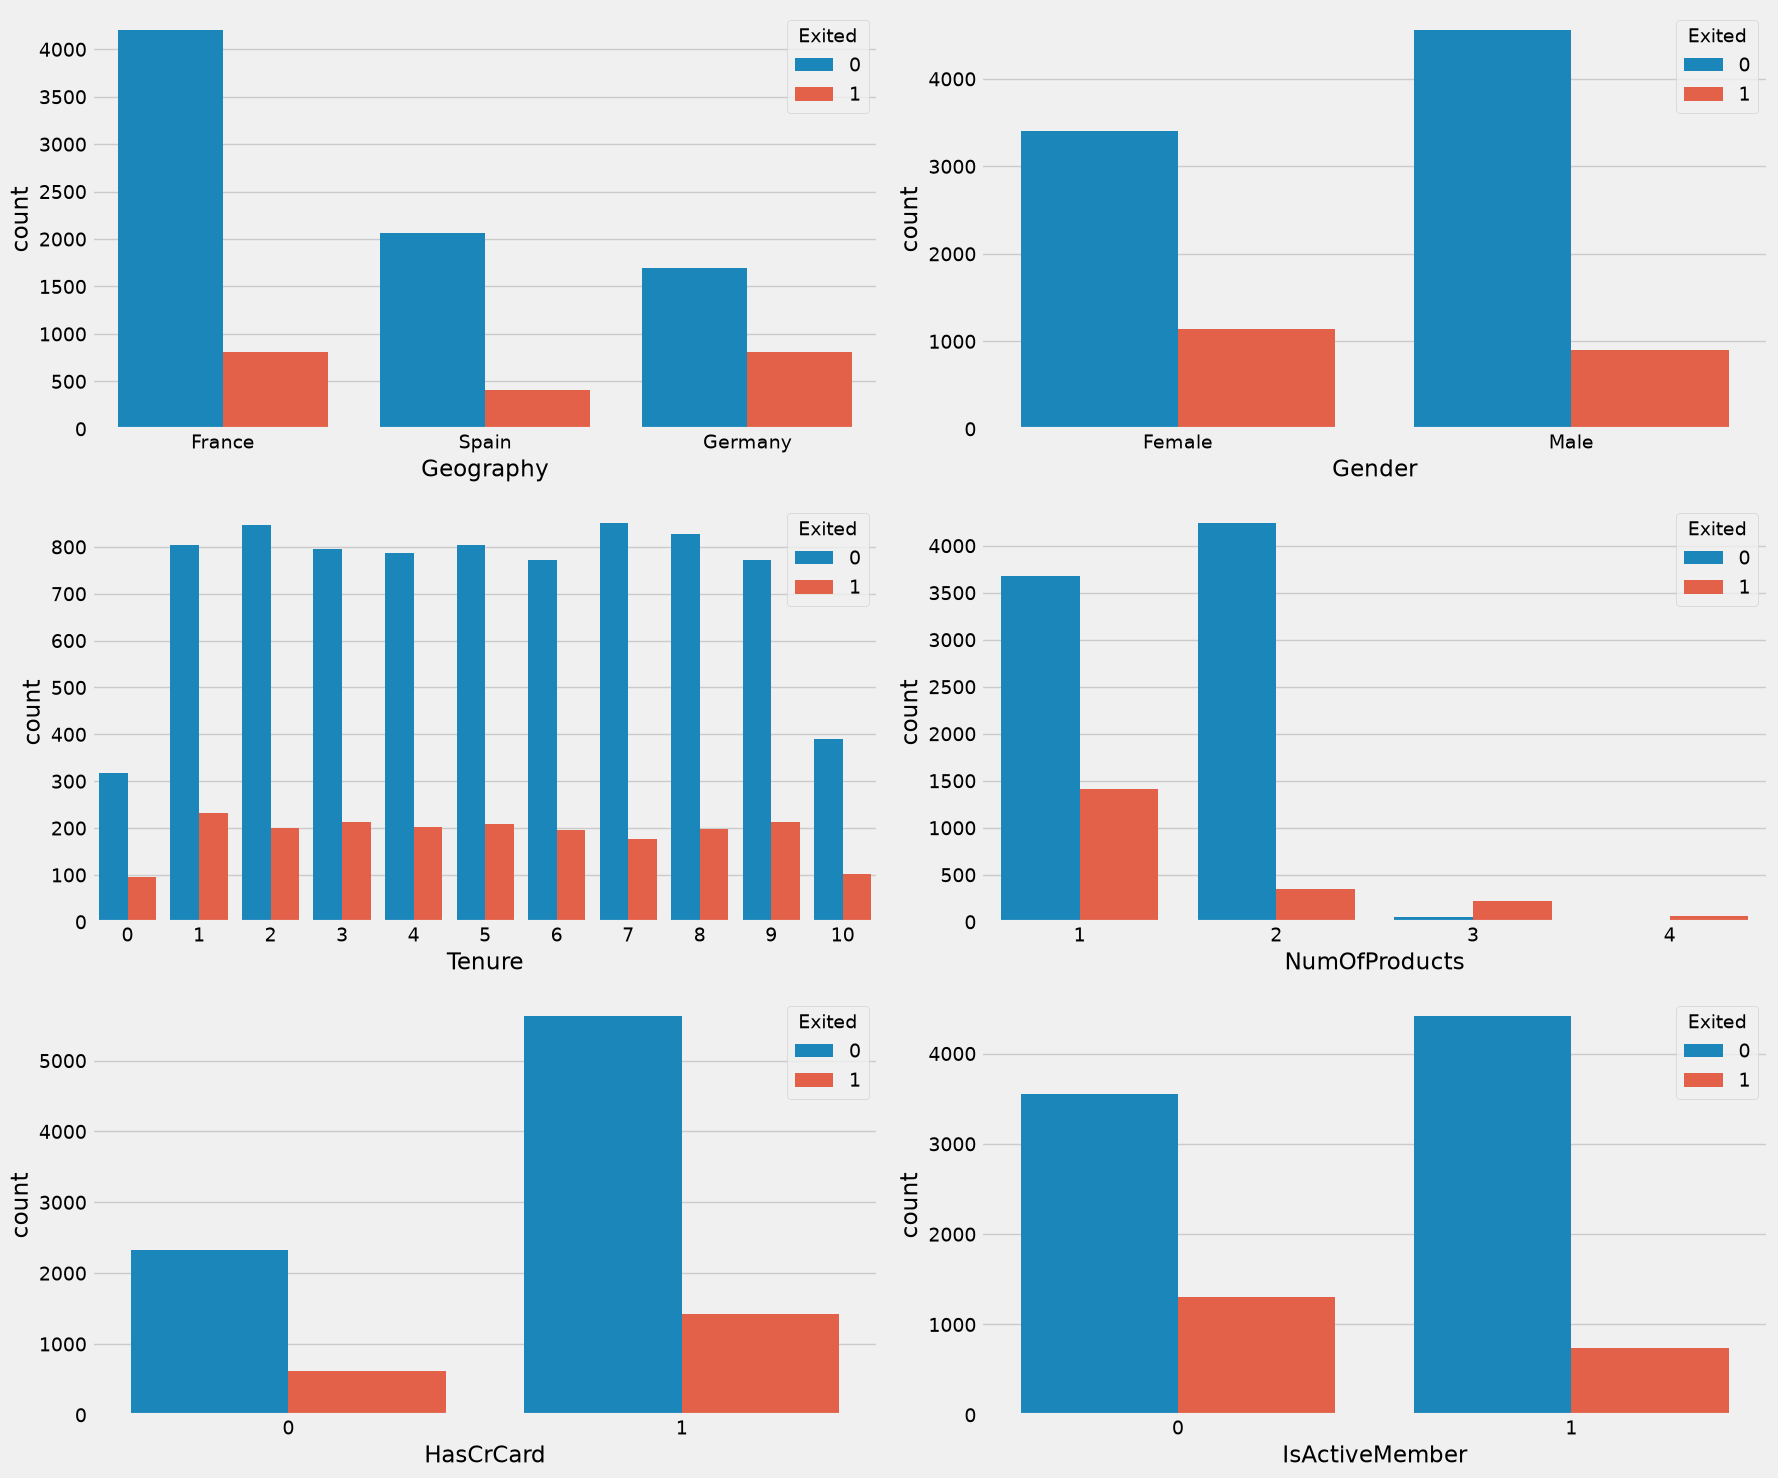

In [42]:
# visualizing the categorical variables

fig, ax = plt.subplots(3, 2, figsize=(18, 15))

sns.countplot(x='Geography', hue = 'Exited', data = df, ax = ax[0][0])
sns.countplot(x='Gender', hue = 'Exited', data = df, ax = ax[0][1])
sns.countplot(x='Tenure', hue = 'Exited', data = df, ax = ax[1][0])
sns.countplot(x='NumOfProducts', hue = 'Exited', data = df, ax = ax[1][1])
sns.countplot(x='HasCrCard', hue = 'Exited', data = df, ax = ax[2][0])
sns.countplot(x='IsActiveMember', hue = 'Exited', data = df, ax = ax[2][1])

plt.tight_layout()
plt.show()

<iframe src="https://www.kaggle.com/embed/niteshyadav3103/customer-churn-prediction-using-ann?cellIds=11&kernelSessionId=79152829" height="300" style="margin: 0 auto; width: 100%; max-width: 950px;" frameborder="0" scrolling="auto" title="Customer Churn Prediction Using ANN"></iframe>

## From above Plots we can conclude that :-
<pre>
<h3>
    -> Majority of the customers are from france but most customers
       which churned are from germany maybe coz of lack of resources
       as there are not many customers
    -> The proportion of male customers churning is also greater than
       that of female customers
    -> Majority of customers have tenure btw 1to9 and churning rate is
       also high btw these tenures.
    -> Most of the customers have 1 or 2 products and most customers which
       churned are having 1 products maybe they are not satisfief 
       so they are churning
    -> Interstingly, majority of customers that churned are those with credit card
       but this can be a coincidence as majority of customers have credit cards.
    -> Unsurprisingly the inactive members have a greater churn and the
       overall proportion of inactive members is also very high.
</pre>

c:\Users\KESHAV\Deep-Learning\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\KESHAV\Deep-Learning\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\KESHAV\Deep-Learning\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\KESHAV\Deep-Learning\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3

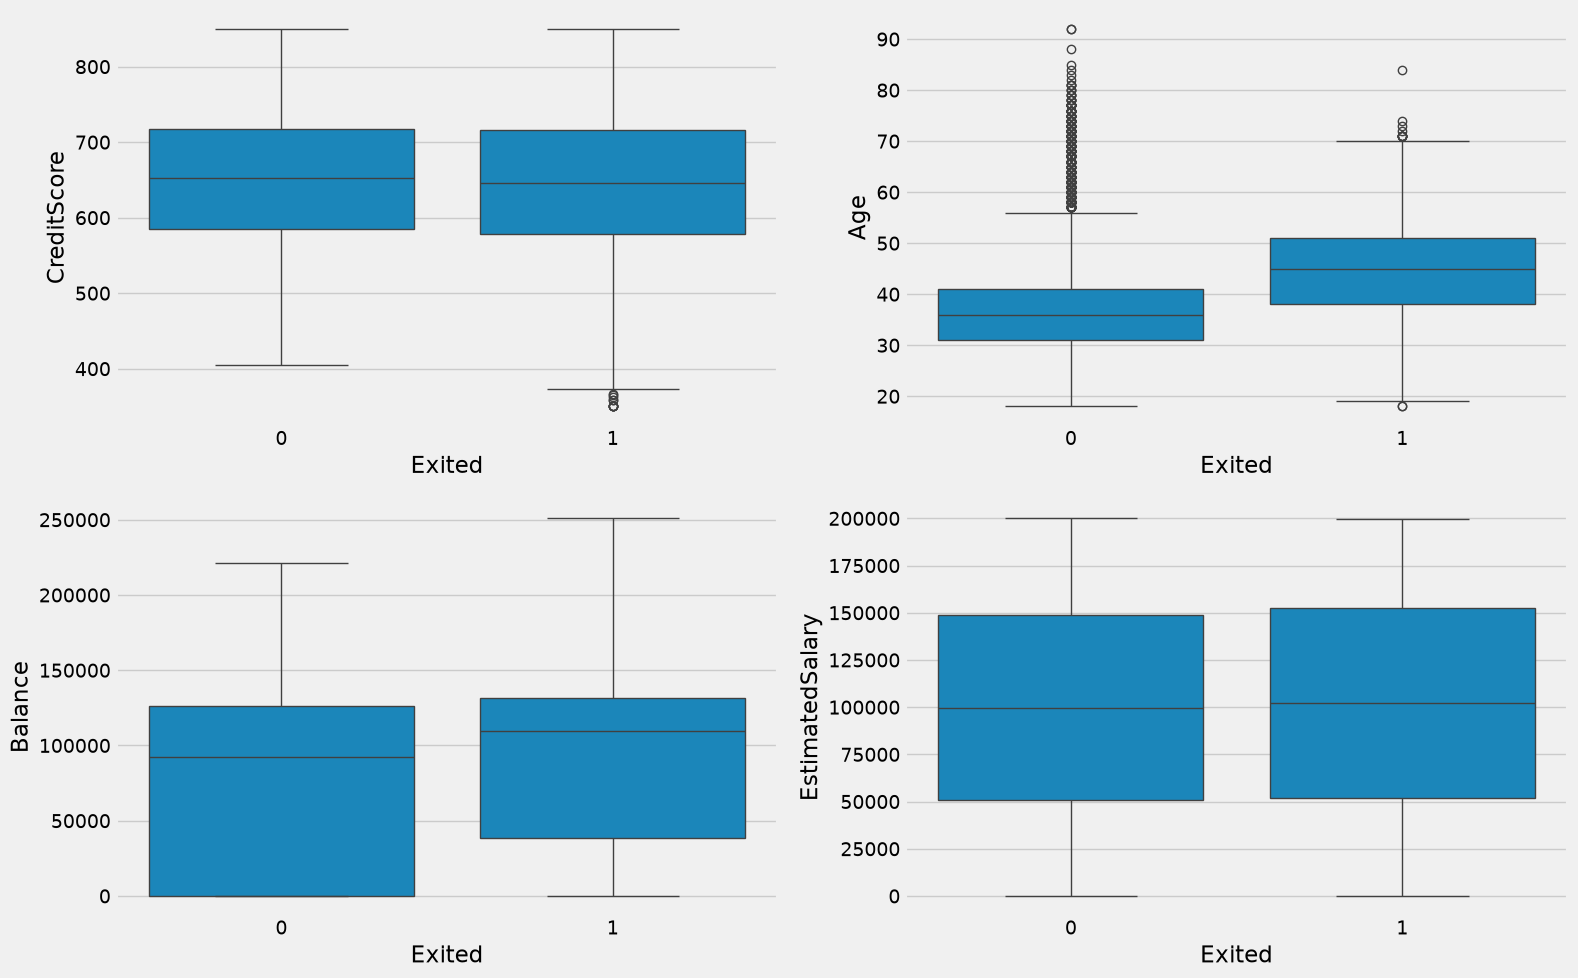

In [43]:
# visualizing continuous variables

fig, ax = plt.subplots(2, 2, figsize = (16, 10))

sns.boxplot(x = 'Exited', y = 'CreditScore', data = df, ax = ax[0][0])
sns.boxplot(x = 'Exited', y = 'Age', data = df, ax = ax[0][1])
sns.boxplot(x = 'Exited', y = 'Balance', data = df, ax = ax[1][0])
sns.boxplot(x = 'Exited', y = 'EstimatedSalary', data = df, ax = ax[1][1])

plt.tight_layout()
plt.show()

<h2 style="color:Green"> From above Plots we can conclude that:-</h2>
<pre><h3 style = "color:blue">
. There is no significant difference in credit score distribution etween custers which are churned or not.
. The older customers are churning more than younger ones.
. Bank is loosing customers with significant bank balance.
. Estimated Salary does not have a significant on the likelihood to churn.
. Interestingly, majority of customers that churned are those with credit cards but this can be a coincidence as majority of customers have credit cards.
. Unsurprisingly the inactive members have a greater churn and the overall proportion of inactive members is also very high.
</h3></style> </pre>

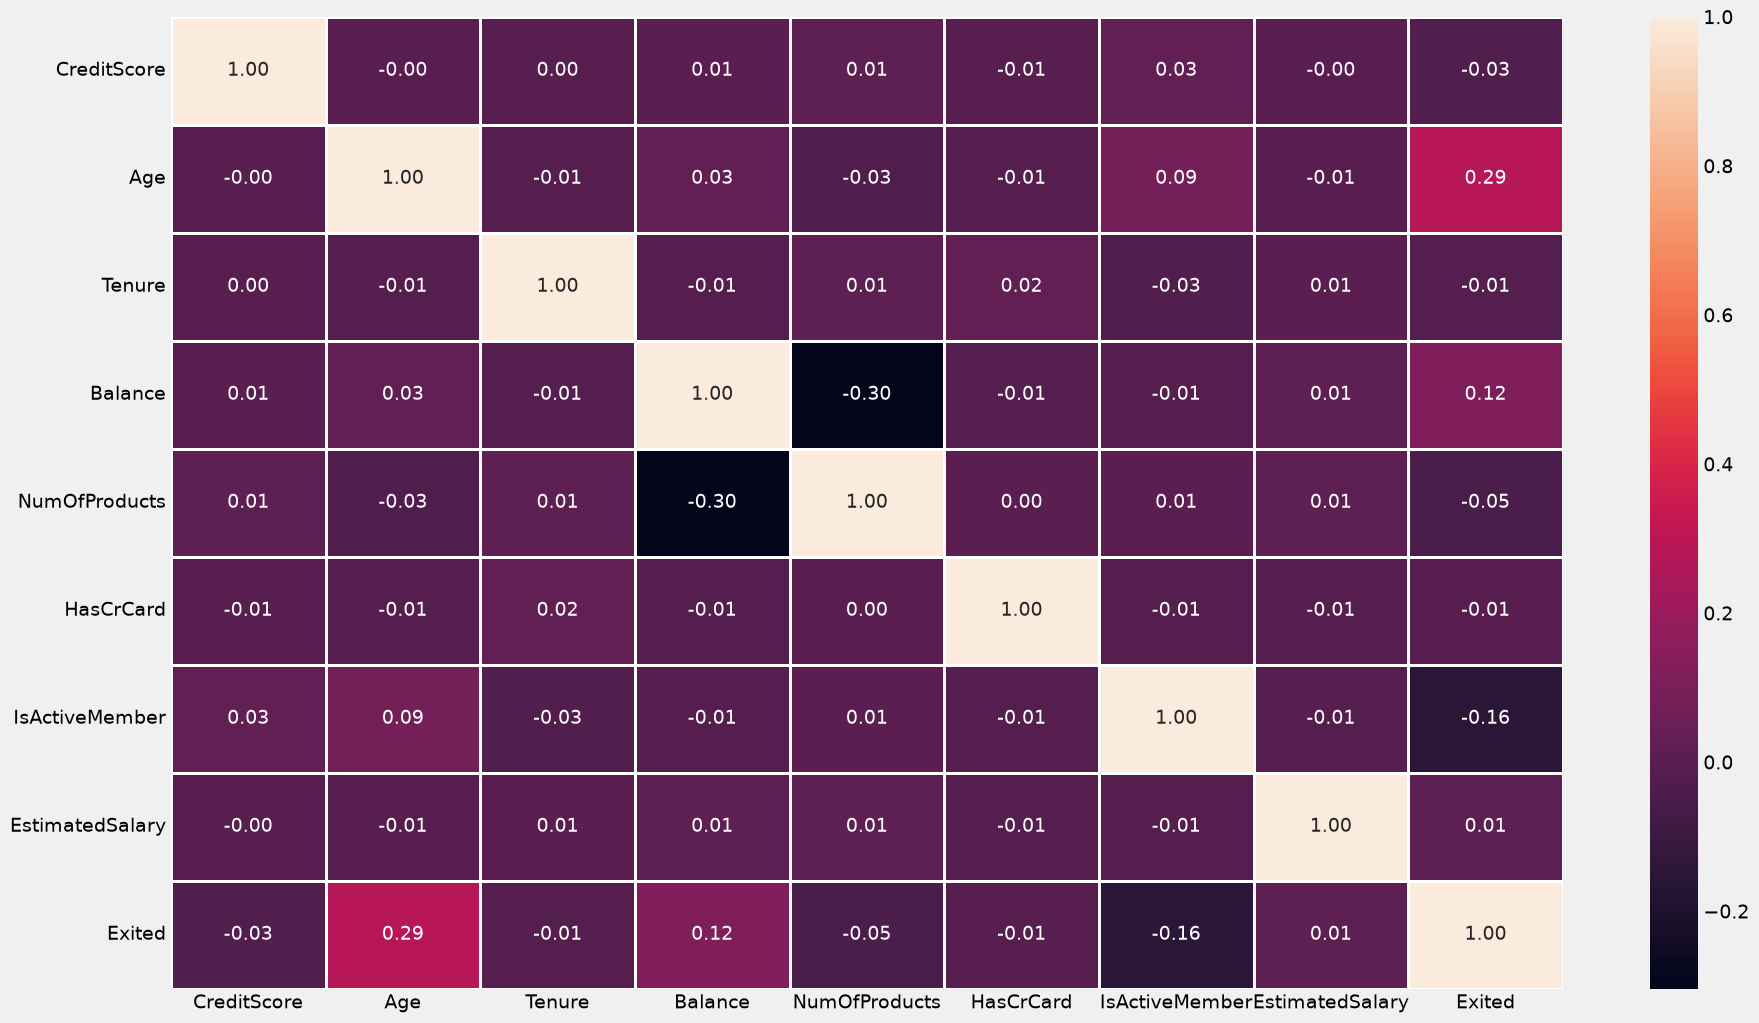

In [44]:
# heatmap

plt.figure(figsize=(20,12))

corr = df.corr(numeric_only =True)

sns.heatmap(corr, linewidths= 1, annot= True, fmt = ".2f")
plt.show()

## We can say that there is no multicolinearity present in data.

In [45]:
df.Geography.value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [46]:
# Encoding categorical variables

df = pd.get_dummies(df, columns=['Geography','Gender'], drop_first=True, dtype=int)
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [47]:
# creating features and label

from tensorflow.keras.utils import to_categorical
X = df.drop('Exited',axis=1)
y=  to_categorical(df.Exited)

In [48]:
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,0,1
9996,516,35,10,57369.61,1,1,1,101699.77,0,0,1
9997,709,36,7,0.00,1,0,1,42085.58,0,0,0
9998,772,42,3,75075.31,2,1,0,92888.52,1,0,1


In [49]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25)

In [50]:
# scaling data

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [51]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train shape: (7500, 11)
X_test shape: (2500, 11)
y_train: (7500, 2)
y_test: (2500, 2)


<h2 style= "text-align:center; color:grey" >Building ANN</h2>

In [52]:
import numpy as np

y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

y_train: (7500,)
y_test: (2500,)


In [53]:
import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import BatchNormalization

In [54]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

model = Sequential([
    Input(shape=(X_train.shape[1],)),  # 11 input features
    Dense(16, activation='relu'),
    Dropout(0.1),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    validation_data = (X_test, y_test),
    epochs=100
)

Epoch 1/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7421 - loss: 0.5553 - val_accuracy: 0.7924 - val_loss: 0.4725
Epoch 2/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8047 - loss: 0.4529 - val_accuracy: 0.8080 - val_loss: 0.4307
Epoch 3/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8145 - loss: 0.4289 - val_accuracy: 0.8204 - val_loss: 0.4099
Epoch 4/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8293 - loss: 0.4130 - val_accuracy: 0.8332 - val_loss: 0.3939
Epoch 5/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8331 - loss: 0.4009 - val_accuracy: 0.8376 - val_loss: 0.3814
Epoch 6/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8457 - loss: 0.3837 - val_accuracy: 0.8416 - val_loss: 0.3734
Epoch 7/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8472 - loss: 0.3764 - val_accuracy: 0.8480 - val_loss: 0.3687
Epoch 8/100
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8471 - loss: 0.3742 - val_accu

Visualizing Training and validation Loss

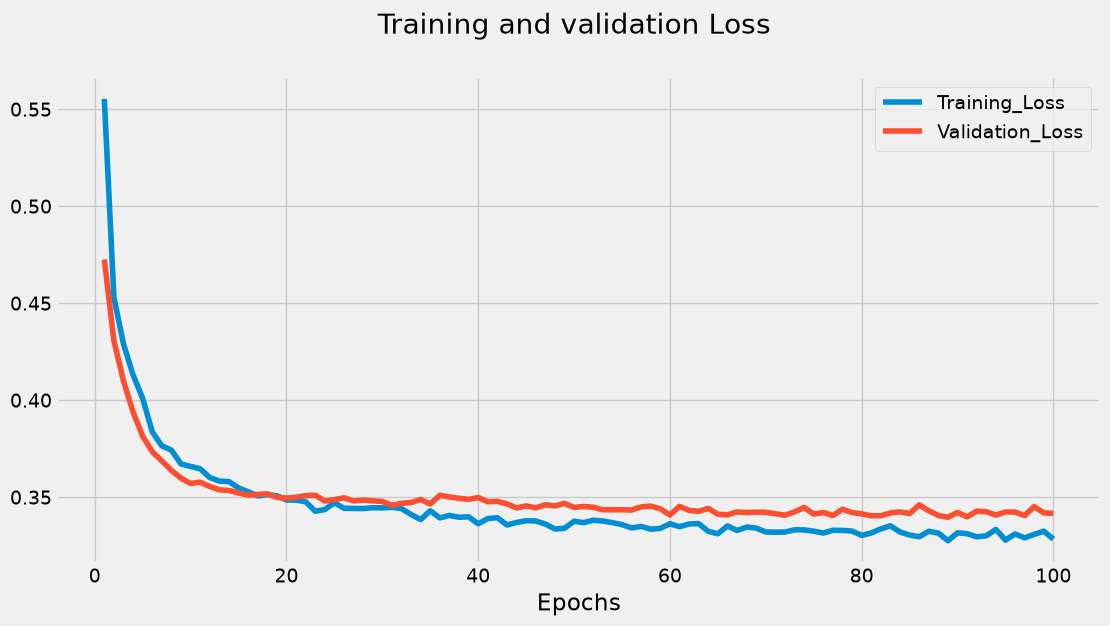

In [55]:
import seaborn as sns
plt.figure(figsize = (12, 6))

train_loss = model_history.history['loss']
val_loss = model_history.history['val_loss']

epoch = range(1, 101)

sns.lineplot(x=epoch,y=train_loss, label = 'Training_Loss')
sns.lineplot(x=epoch,y=val_loss, label = 'Validation_Loss')

plt.title('Training and validation Loss \n')
plt.xlabel('Epochs')
plt.legend()
plt.show()

## Visualizing Training and Validation accuracy

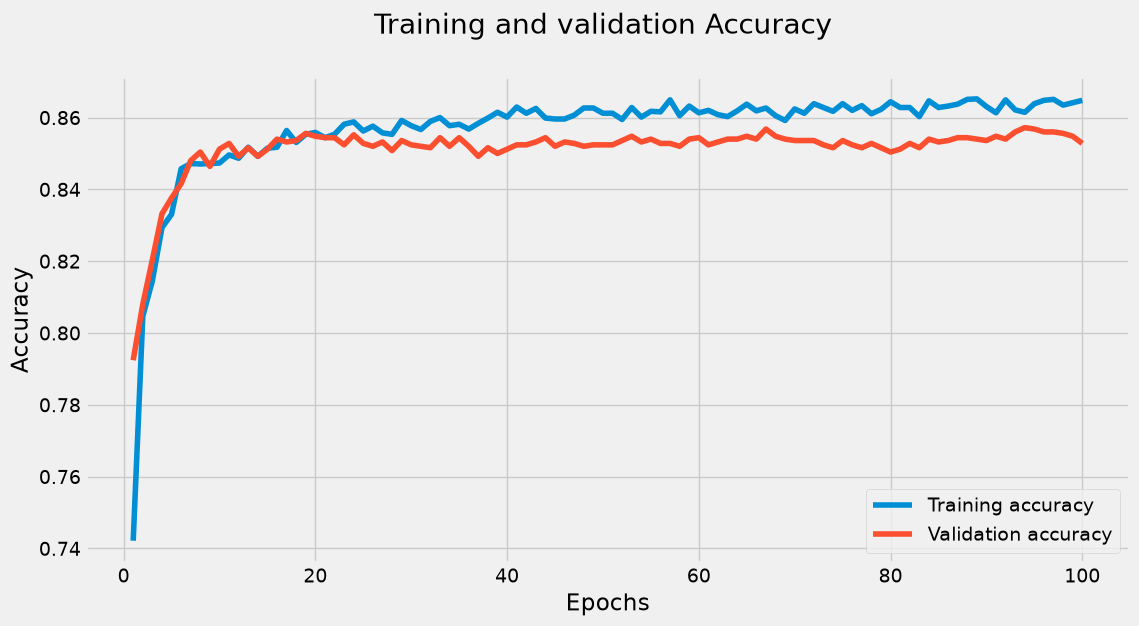

In [56]:
plt.figure(figsize =(12,6))

train_loss = model_history.history['accuracy']
val_loss = model_history.history['val_accuracy']

epoch = range(1, 101)

sns.lineplot(x = epoch, y = train_loss, label = 'Training accuracy')
sns.lineplot(x = epoch, y = val_loss, label = 'Validation accuracy')

plt.title('Training and validation Accuracy \n')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

In [57]:
acc = model.evaluate(X_test, y_test)
print(f'Accuracy of model is {acc}')

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8528 - loss: 0.3416
Accuracy of model is [0.3416386842727661, 0.8528000116348267]


In [58]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013 (3.96 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 676 (2.64 KB)

In [62]:
from tensorflow.keras.utils import plot_model
plot_model(model, show_shapes = True)

You must install pydot (`pip install pydot`) for `plot_model` to work.
